## IMPORTS

In [1]:
from pathlib import Path

import uxarray as ux
import xarray as xr
import numpy as np

## DASK CONFIG

In [2]:
from dask.distributed import Client

# client = Client(n_workers=1, threads_per_worker=6, processes=False, memory_limit="100GB")
client = Client(n_workers=6, threads_per_worker=2, memory_limit="12GB")
client.dashboard_link

'/node/crhtc68.hpc.ucar.edu/2846/proxy/8787/status'

In [3]:
# The distributed.shuffle messages can be too much - suppress them!
import logging
logging.getLogger("distributed.shuffle").setLevel(logging.ERROR)

In [4]:
TIME_CHUNK = 40
FACE_CHUNK = 2000

## RUN CONFIG (Native Grid)

In [5]:
# Determine if notebook is to be run on local device or HPC
RUN_ON = 'hpc'  # Notebook to be run on either of "local" | "hpc"

if RUN_ON == 'local':
    KERCHUNK_PATH = "https://data.gdex.ucar.edu/d651007/kerchunk/"
    KERCHUNK_ACCESS = "-remote-osdf"
    KERCHUNK_REMOTE_PROTOCOL = "osdf"
    GRID_FILE = "ne120np4_pentagons_100310.nc"  # Local
elif RUN_ON == 'hpc':
    KERCHUNK_PATH = "/gdex/data/d651007/kerchunk/"
    KERCHUNK_ACCESS = ""  # Kerchunk dataset access, either of "" | "-remote-https" | "-remote-osdf"
    KERCHUNK_REMOTE_PROTOCOL = "file"
    # GRID_FILE = "/glade/p/cesmdata/cseg/inputdata/share/scripgrids/ne120np4_pentagons_100310.nc"  # Glade - this is older?
    GRID_FILE = "/glade/campaign/cesm/cesmdata/cseg/inputdata/share/scripgrids/ne120np4_pentagons_100310.nc"

In [6]:
MEMBERS = range(2, 11)   # member 1 has no 6-hourly stream

MODEL = "atm"
FREQ = "hour_6"  # or "day_1"
VAR = "PRECT"
VARS = ['TS', 'PSL', 'PRECT']

EXTREME_MEMBER = 10  # to be used for one-member cases

In [7]:
T_START = "1979-01-01"
T_END = "1988-12-31"

In [8]:
# Unit conversions

SEC_PER_DAY = 24 * 3600  # 6-hourly output
M_TO_MM = 1000.0

# there are four 6-hour timesteps per day, and exactly 365 days per year in this data;
# it avoids dealing with leap years, and has cftime.DatetimeNoLeap time coordinates.
STEPS_PER_DAY = 4
DAYS_PER_YEAR = 365
STEPS_PER_YEAR = STEPS_PER_DAY * DAYS_PER_YEAR

## UXARRAY (Explore Grid and a single ensemble member)

### Grid

In [9]:
%%time
uxgrid = ux.open_grid(GRID_FILE)
uxgrid

/glade/work/oero/conda-envs/uxarray-usclivar/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


CPU times: user 2.6 s, sys: 885 ms, total: 3.49 s
Wall time: 18.9 s


<uxarray.Grid>
Original Grid Type: Scrip
Grid Dimensions:
  * n_node: 780456
  * n_face: 777602
  * n_max_face_nodes: 5
Grid Coordinates (Spherical):
  * node_lon: (780456,)
  * node_lat: (780456,)
  * face_lon: (777602,)
  * face_lat: (777602,)
Grid Coordinates (Cartesian):
Grid Connectivity Variables:
  * face_node_connectivity: (777602, 5)
Grid Descriptor Variables:

### Single ensemble member

In [10]:
# A single ensemble file for sampling
data_filename = "b.e13.BHISTC5.ne120_t12.cesm-ihesp-hires1.0.46-1920-2005." + f"{EXTREME_MEMBER:03d}" + "." + MODEL + "." + FREQ + KERCHUNK_ACCESS + ".parq"
data_file = KERCHUNK_PATH + data_filename

In [11]:
%%time
# One ensemble member
uxds = ux.open_dataset(
    GRID_FILE, 
    data_file, 
    engine="kerchunk", 
    decode_timedelta=False, 
    storage_options={"remote_protocol": KERCHUNK_REMOTE_PROTOCOL},
    chunks={}
)
uxds

CPU times: user 3.89 s, sys: 1.25 s, total: 5.14 s
Wall time: 9.5 s


<xarray.UxDataset> Size: 22TB
Dimensions:        (time: 125561, n_face: 777602, cosp_ht: 40, nbnd: 2,
                    cosp_prs: 7, cosp_sr: 15, cosp_tau: 7, ilev: 31, lev: 30,
                    cosp_scol: 50, cosp_sza: 5)
Coordinates:
  * time           (time) object 1MB 1920-01-01 00:00:00 ... 2006-01-01 00:00:00
  * cosp_ht        (cosp_ht) float64 320B 240.0 720.0 ... 1.848e+04 1.896e+04
  * cosp_prs       (cosp_prs) float64 56B 900.0 740.0 620.0 ... 375.0 245.0 90.0
  * cosp_sr        (cosp_sr) float64 120B 0.605 2.1 4.0 ... 70.0 539.5 1.004e+03
  * cosp_tau       (cosp_tau) float64 56B 0.15 0.8 2.45 6.5 16.2 41.5 219.5
  * ilev           (ilev) float64 248B 2.255 5.032 10.16 ... 967.5 985.1 1e+03
  * lev            (lev) float64 240B 3.643 7.595 14.36 ... 957.5 976.3 992.6
  * cosp_scol      (cosp_scol) int32 200B 1 2 3 4 5 6 7 ... 44 45 46 47 48 49 50
  * cosp_sza       (cosp_sza) float64 40B 0.0 15.0 30.0 45.0 60.0
Dimensions without coordinates: n_face, nbnd
Data variables: (12/83)
    CLDTOT         (time, n_face) float32 391GB dask.array<chunksize=(1, 777602), meta=np.ndarray>
    FLDS           (time, n_face) float32 391GB dask.array<chunksize=(1, 777602), meta=np.ndarray>
    FLDSC          (time, n_face) float32 391GB dask.array<chunksize=(1, 777602), meta=np.ndarray>
    FLNS           (time, n_face) float32 391GB dask.array<chunksize=(1, 777602), meta=np.ndarray>
    FLUT           (time, n_face) float32 391GB dask.array<chunksize=(1, 777602), meta=np.ndarray>
    FSDS           (time, n_face) float32 391GB dask.array<chunksize=(1, 777602), meta=np.ndarray>
    ...             ...
    ntrm           (time) float64 1MB dask.array<chunksize=(1,), meta=np.ndarray>
    ntrn           (time) float64 1MB dask.array<chunksize=(1,), meta=np.ndarray>
    sol_tsi        (time) float64 1MB dask.array<chunksize=(512,), meta=np.ndarray>
    time_bnds      (time, nbnd) object 2MB dask.array<chunksize=(1, 2), meta=np.ndarray>
    uIVT           (time, n_face) float32 391GB dask.array<chunksize=(1, 777602), meta=np.ndarray>
    vIVT           (time, n_face) float32 391GB dask.array<chunksize=(1, 777602), meta=np.ndarray>
Attributes:
    np:               4
    ne:               120
    Conventions:      CF-1.0
    source:           CAM
    case:             b.e13.BHISTC5.ne120_t12.cesm-ihesp-hires1.0.46-1920-200...
    title:            UNSET
    logname:          fredc
    host:             derecho1
    Version:          $Name$
    revision_Id:      $Id$
    initial_file:     B.E.13.BHISTC5.ne120_t12.sehires38.003.sunway.cam.i.192...
    topography_file:  /glade/campaign/cesm/cesmdata/inputdata/atm/cam/topo/US...

#### Naive plot of a member's PRECT

In [12]:
%%time
uxds[VAR].isel(time=0).plot()

CPU times: user 21.2 s, sys: 1.63 s, total: 22.8 s
Wall time: 40.1 s


:Image   [x,y]   (x_y PRECT)

## YEARLY GLOBAL STATS

In [13]:
uxds_yearly = uxds[VARS].isel(time=slice(None, None, STEPS_PER_YEAR)).chunk()
print(f'Size: {uxds_yearly.nbytes/1e9:.2f} GB')
uxds_yearly

Size: 0.81 GB


<xarray.UxDataset> Size: 812MB
Dimensions:  (time: 87, n_face: 777602)
Coordinates:
  * time     (time) object 696B 1920-01-01 00:00:00 ... 2006-01-01 00:00:00
Dimensions without coordinates: n_face
Data variables:
    TS       (time, n_face) float32 271MB dask.array<chunksize=(1, 777602), meta=np.ndarray>
    PSL      (time, n_face) float32 271MB dask.array<chunksize=(1, 777602), meta=np.ndarray>
    PRECT    (time, n_face) float32 271MB dask.array<chunksize=(1, 777602), meta=np.ndarray>
Attributes:
    np:               4
    ne:               120
    Conventions:      CF-1.0
    source:           CAM
    case:             b.e13.BHISTC5.ne120_t12.cesm-ihesp-hires1.0.46-1920-200...
    title:            UNSET
    logname:          fredc
    host:             derecho1
    Version:          $Name$
    revision_Id:      $Id$
    initial_file:     B.E.13.BHISTC5.ne120_t12.sehires38.003.sunway.cam.i.192...
    topography_file:  /glade/campaign/cesm/cesmdata/inputdata/atm/cam/topo/US...

In [14]:
%%time 
uxds_yearly = uxds_yearly.load()

2026-10-16 21:02:57,102 - distributed.worker.memory - WARNING - Unmanaged memory use is high. This may indicate a memory leak or the memory may not be released to the OS; see https://distributed.dask.org/en/latest/worker-memory.html#memory-not-released-back-to-the-os for more information. -- Unmanaged memory: 7.93 GiB -- Worker memory limit: 11.18 GiB
2026-10-16 21:02:57,449 - distributed.worker.memory - WARNING - Unmanaged memory use is high. This may indicate a memory leak or the memory may not be released to the OS; see https://distributed.dask.org/en/latest/worker-memory.html#memory-not-released-back-to-the-os for more information. -- Unmanaged memory: 7.74 GiB -- Worker memory limit: 11.18 GiB
2026-10-16 21:02:58,001 - distributed.worker.memory - WARNING - Unmanaged memory use is high. This may indicate a memory leak or the memory may not be released to the OS; see https://distributed.dask.org/en/latest/worker-memory.html#memory-not-released-back-to-the-os for more information. --

CPU times: user 22 s, sys: 888 ms, total: 22.9 s
Wall time: 26.8 s


In [15]:
%%time
# naive average: just take mean of all faces across the globe
mean_yearly = uxds_yearly.mean('n_face')

CPU times: user 205 ms, sys: 4.01 ms, total: 209 ms
Wall time: 200 ms


In [16]:
%%time
# face-area-weighted mean: wmean = ds.weighted_mean()
# (not yet implemented on UxDataset, so can't run that yet.
# workaround: convert to UxDataset, take mean, then convert back.)
weighted_mean_yearly = uxds_yearly.to_array(dim='variable').weighted_mean().to_dataset(dim='variable')

# Also, similar workaround as above: convert to xarray.DataArray
# weighted_mean_yearly = weighted_mean_yearly.to_xarray()
# wmean_jan1 = weighted_mean_yearly  # alias so we can still refer back to this in later sections.

CPU times: user 1.17 s, sys: 478 ms, total: 1.65 s
Wall time: 1.18 s


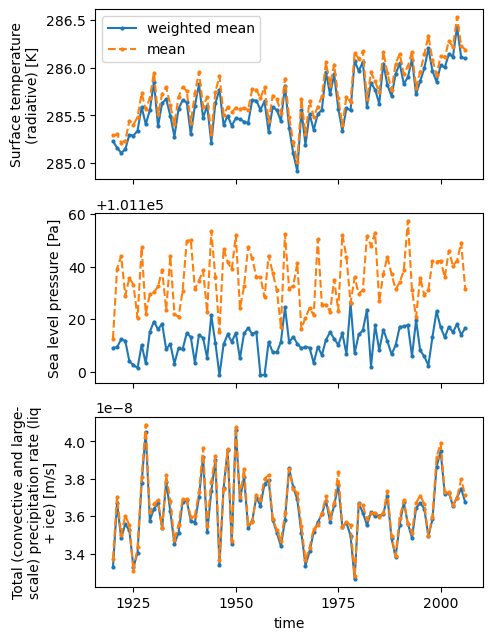

In [17]:
import matplotlib.pyplot as plt

# visualize the results (pure xarray; nothing in this cell uses uxarray anymore)
fig, axes = plt.subplots(nrows=len(VARS), ncols=1, figsize=(5, 2.5*len(VARS)))
for ax, var in zip(axes, VARS):
    weighted_mean_yearly[var].to_xarray().plot(ax=ax, label="weighted mean", marker='o', ms=2)
    mean_yearly[var].to_xarray().plot(ax=ax, label="mean", ls='--', marker='o', ms=2)
# labeling & formatting
axes[0].legend()
for ax in axes[:-1]:
    ax.set(xlabel="", xticklabels=[])

## WHOLE ENSEMBLE

In [18]:
# Helper function to open a single ensemble member
def open_member(member):
    hits = sorted(Path(KERCHUNK_PATH).rglob(f"*.{member:03d}.{MODEL}.{FREQ}{KERCHUNK_ACCESS}.parq"))

    if not hits:
        return None
    assert len(hits) == 1, f"expected exactly one file for member {member}, found {len(hits)}: {hits}"

    return ux.open_dataset(
        GRID_FILE, 
        str(hits[0]), 
        engine="kerchunk", 
        decode_timedelta=False, 
        storage_options={"remote_protocol": KERCHUNK_REMOTE_PROTOCOL},
        chunks={"time": TIME_CHUNK}
    )

### Read the ensemble members

In [19]:
%%time
# Opened lazily only, no eager persist here. Native storage isn't spatially
# chunked (chunks=[1, 777602], one full-globe row per timestep), so every chunk
# read pays a ~33x read/decompress tax before the CONUS mask discards ~97% of it.
members = {m: da for m in MEMBERS if (da := open_member(m)) is not None}

/glade/work/oero/conda-envs/uxarray-usclivar/lib/python3.14/site-packages/uxarray/core/utils.py:37: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 40. This could degrade performance. Instead, consider rechunking after loading.
  return xr.open_dataset(filename_or_obj, chunks=chunks, **kwargs)
/glade/work/oero/conda-envs/uxarray-usclivar/lib/python3.14/site-packages/uxarray/core/utils.py:37: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 40. This could degrade performance. Instead, consider rechunking after loading.
  return xr.open_dataset(filename_or_obj, chunks=chunks, **kwargs)
/glade/work/oero/conda-envs/uxarray-usclivar/lib/python3.14/site-packages/uxarray/core/utils.py:37: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 40. This could degrade performance. Instead, consider rechunking after loading.
  return xr.open_dat

CPU times: user 30 s, sys: 21 s, total: 50.9 s
Wall time: 1min 10s


#### CONUS - region to subset

In [21]:
lat, lon = uxgrid.face_lat.values, uxgrid.face_lon.values
# lon180 = ((lon + 180) % 360) - 180

conus = (lat > 25) & (lat < 50) & (lon > -125) & (lon < -66)

In [22]:
%%time
members = {key: ds[VAR].sel(time=slice(T_START, T_END)).isel(n_face=conus) for key, ds in members.items()}

CPU times: user 1.48 s, sys: 114 ms, total: 1.6 s
Wall time: 2.24 s


In [23]:
%%time
# Persist just this one member now, staged at the point it's first needed (it's
# reused again below for extreme_metrics) — instead of persisting all 9 members
# upfront, which concentrated the ~33x full-globe read/decompress tax into one
# burst across the whole cluster.
members[EXTREME_MEMBER] = members[EXTREME_MEMBER].persist()

CPU times: user 6.19 ms, sys: 645 μs, total: 6.83 ms
Wall time: 6.55 ms


## PRECIPITATION

In [24]:
print("Source units:", members[EXTREME_MEMBER].attrs.get("units", "unknown"))

# CESM/CAM PRECT is a total precipitation rate in m/s -> convert to mm/day
precip_mm = members[EXTREME_MEMBER] * M_TO_MM * SEC_PER_DAY
precip_mm.attrs["units"] = "mm/day"
precip_mm

Source units: m/s


<xarray.UxDataArray 'PRECT' (time: 14600, n_face: 23243)> Size: 1GB
dask.array<mul, shape=(14600, 23243), dtype=float32, chunksize=(40, 23243), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) object 117kB 1979-01-01 00:00:00 ... 1988-12-31 18:00:00
Dimensions without coordinates: n_face
Attributes:
    units:      mm/day
    long_name:  Total (convective and large-scale) precipitation rate (liq + ...

In [25]:
%%time
precip_mm.mean(dim="time").plot(
    cmap="YlGnBu",
    features=["borders", "coastline"],
    title=f"6-hourly PRECT (mm/day) - 10-yr avg — Ensemble member {EXTREME_MEMBER} (USCLIVAR ne120 native grid)" ,
)

2026-10-16 21:04:39,396 - distributed.worker.memory - WARNING - Worker is at 80% memory usage. Pausing worker.  Process memory: 8.99 GiB -- Worker memory limit: 11.18 GiB
2026-10-16 21:04:39,412 - distributed.worker.memory - WARNING - Worker is at 13% memory usage. Resuming worker. Process memory: 1.46 GiB -- Worker memory limit: 11.18 GiB


CPU times: user 44.8 s, sys: 2.93 s, total: 47.7 s
Wall time: 2min 1s


:Overlay
   .Image.I     :Image   [Longitude,Latitude]   (Longitude_Latitude PRECT)
   .Coastline.I :Feature   [Longitude,Latitude]
   .Borders.I   :Feature   [Longitude,Latitude]

## EXTREME PRECIPITATION METRICS

Using the 6-hourly `PRECT` of ensemble members, compute per-gridcell extreme precipitation metrics over CONUS and map their spatial distribution on the native ne120 mesh.

In [26]:
# Helper function to calculate a couple of preferred percentiles, max, and the total 95th-percentile

def extreme_precip_metrics(uxda, high_q=0.95, extreme_q=0.99, face_chunk=FACE_CHUNK):
    """Per-gridcell extreme precipitation metrics along the "time" dimension."""
    
    uxda = uxda.chunk({"time": -1, "n_face": face_chunk})

    q_high = uxda.quantile(high_q, dim="time", skipna=True).drop_vars("quantile")
    q_extreme = uxda.quantile(extreme_q, dim="time", skipna=True).drop_vars("quantile")
    uxda_max = uxda.max(dim="time", skipna=True)

    above_high_total = uxda.where(uxda >= q_high).sum(dim="time", skipna=True)
    total = uxda.sum(dim="time", skipna=True)
    r95ptot = (above_high_total / total) * 100

    freq_extreme = (uxda >= q_extreme).sum(dim="time") / uxda.sizes["time"] * 100

    metrics = xr.Dataset(
        {
            f"p{int(high_q * 100)}": q_high,
            f"p{int(extreme_q * 100)}": q_extreme,
            "max": uxda_max,
            "r95ptot": r95ptot,
            f"freq_p{int(extreme_q * 100)}": freq_extreme,
        }
    )
    return ux.UxDataset(metrics, uxgrid=uxda.uxgrid)

In [27]:
%%time
extreme_metrics = extreme_precip_metrics(precip_mm).compute()


CPU times: user 539 ms, sys: 62.3 ms, total: 601 ms
Wall time: 3.6 s


### 95th and 99th percentile, max, and r95ptot over 10 years

In [28]:
extreme_metrics["p95"].plot(
    cmap="YlGnBu",
    features=["borders", "coastline"],
    title=f"6-hourly PRECT (mm/day) - 95th percentile (10 year) — ensemble member {EXTREME_MEMBER} (USCLIVAR ne120 native grid)",
)


:Overlay
   .Image.I     :Image   [Longitude,Latitude]   (Longitude_Latitude p95)
   .Coastline.I :Feature   [Longitude,Latitude]
   .Borders.I   :Feature   [Longitude,Latitude]

In [29]:
extreme_metrics["p99"].plot(
    cmap="YlGnBu",
    features=["borders", "coastline"],
    title=f"6-hourly PRECT (mm/day) - 99th percentile (10 year) — ensemble member {EXTREME_MEMBER} (USCLIVAR ne120 native grid)",
)


:Overlay
   .Image.I     :Image   [Longitude,Latitude]   (Longitude_Latitude p99)
   .Coastline.I :Feature   [Longitude,Latitude]
   .Borders.I   :Feature   [Longitude,Latitude]

In [30]:
extreme_metrics["max"].plot(
    cmap="magma",
    features=["borders", "coastline"],
    title=f"6-hourly PRECT (mm/day) - 10-year maximum — ensemble member {EXTREME_MEMBER} (USCLIVAR ne120 native grid)",
)


:Overlay
   .Image.I     :Image   [Longitude,Latitude]   (Longitude_Latitude max)
   .Coastline.I :Feature   [Longitude,Latitude]
   .Borders.I   :Feature   [Longitude,Latitude]

In [31]:
extreme_metrics["r95ptot"].plot(
    cmap="YlGnBu",
    features=["borders", "coastline"],
    title=f"6-hourly PRECT (mm/day) - % of total precip from ≥ p95 — ensemble member {EXTREME_MEMBER} (USCLIVAR ne120 grid)",
)


:Overlay
   .Image.I     :Image   [Longitude,Latitude]   (Longitude_Latitude r95ptot)
   .Coastline.I :Feature   [Longitude,Latitude]
   .Borders.I   :Feature   [Longitude,Latitude]

### Ensemble mean of the 99th percentile

In [32]:
%%time
# Build the p99 metric lazily for every available member, then compute the mean once 
# so dask can schedule the whole ensemble mean as a single parallel graph.

member_p99 = {}
for m, uxda in members.items():
    if m == EXTREME_MEMBER:
        member_p99[m] = extreme_metrics["p99"]
        continue
    precip = (uxda * M_TO_MM * SEC_PER_DAY).chunk({"time": -1, "n_face": FACE_CHUNK})
    member_p99[m] = precip.quantile(0.99, dim="time", skipna=True).drop_vars("quantile")

ensemble_p99 = xr.concat(list(member_p99.values()), dim="member").assign_coords(
    member=list(member_p99.keys())
)

ensemble_p99_mean = ensemble_p99.mean(dim="member").compute()

ensemble_p99_mean_ux = ux.UxDataArray(
    ensemble_p99_mean, uxgrid=members[EXTREME_MEMBER].uxgrid, name="p99_ensemble_mean"
)

CPU times: user 6min 10s, sys: 20.3 s, total: 6min 30s
Wall time: 15min 54s


In [33]:
ensemble_p99_mean_ux.plot(
    cmap="YlGnBu",
    features=["borders", "coastline"],
    title="6-hourly PRECT (mm/day) - 99th percentile (10 year) — Ensemble mean (USCLIVAR ne120 native grid)",
)


:Overlay
   .Image.I     :Image   [Longitude,Latitude]   (Longitude_Latitude p99_ensemble_mean)
   .Coastline.I :Feature   [Longitude,Latitude]
   .Borders.I   :Feature   [Longitude,Latitude]

## NATIVE GRID vs CONSERVATIVELY REMAPPED GRID

To see the effect of conservative regridding, we will now start look ating the conservatively regridded dataset for the workshop as well, and we will take the difference between the results from the native grid and this regridded (lat/lon) grid — this isolates how much conservative aggregation smooths out extremes relative to the native resolution.

### USCLIVAR's regridded data
Read in the regridded CESM-HR global 6-hourly variables used to identify and track extreme weather events (`data_file_regridded_large`) below. The [workshop's website](https://usclivar.org/meetings/high-resolution-modeling-data-access) points to Globus Guest Collections for the datasets, but we will access them through Glade

In [34]:
# High-frequency (6-hr) outputs for extreme weather event identification and tracking:
data_file_regridded_large = '/glade/campaign/univ/utam0017/Extreme_Weather_Risk_dataset'

# # There was also a smaller dataset intended for the practicum (not used for this notebook):
# data_file_regridded_small = '/glade/campaign/univ/utam0017/High-Resolution_Modeling_Workshop_MESACLIP_dataset'

In [35]:
import re

_REGRID_MEMBER_TEMPLATE = "b.e13.HF-TNST.rcp85.ne120_t12.1920-2100.{member:03d}"
_REGRID_FILENAME_RE = re.compile(r"\.(\d{10})-(\d{10})\.nc$")


def open_regridded_member(member, lat_slice=None, lon_slice=None):
    """Read one ensemble member's externally-regridded (0.25 deg lat/lon) field."""
    
    member_dir = Path(data_file_regridded_large) / _REGRID_MEMBER_TEMPLATE.format(member=member) / VAR
    hits = sorted(member_dir.glob(f"*.{VAR}.latlon_0.25x0.25_0E.*.nc"),
                  key=lambda p: _REGRID_FILENAME_RE.search(p.name).group(1))
    if not hits:
        return None

    t_start_key, t_end_key = T_START.replace("-", ""), T_END.replace("-", "")
    hits = [
        p for p in hits
        if not (_REGRID_FILENAME_RE.search(p.name).group(2)[:8] < t_start_key
                or _REGRID_FILENAME_RE.search(p.name).group(1)[:8] > t_end_key)
    ]

    ds = xr.open_mfdataset(
        hits,
        combine="nested",
        concat_dim="time",
        decode_times=xr.coders.CFDatetimeCoder(use_cftime=True),
        decode_timedelta=False,
        # Native chunks are [1, 720, 1440] — one full-globe row per timestep, same
        # "not spatially chunked" situation as the kerchunk source above.
        chunks={"time": 40},
        data_vars="minimal", coords="minimal", compat="override",
    )
    
    da = ds[VAR].sel(time=slice(T_START, T_END))
    # lat/lon here are a genuine regular grid, so a contiguous slice() is basic
    # indexing dask can push down cheaply — unlike the CONUS boolean mask on the
    # native ne120 mesh, this doesn't force reading the full globe per timestep.
    if lat_slice is not None:
        da = da.sel(lat=lat_slice)
    if lon_slice is not None:
        da = da.sel(lon=lon_slice)
    return da

In [36]:
# CONUS bbox in this dataset's 0-360 longitude convention (native mesh used -125/-66)
precip_regridded_raw = open_regridded_member(
    EXTREME_MEMBER, lat_slice=slice(25, 50), lon_slice=slice(235, 294),
)
precip_regridded_mm = precip_regridded_raw * M_TO_MM * SEC_PER_DAY
precip_regridded_mm.attrs["units"] = "mm/day"
precip_regridded_mm

/glade/derecho/scratch/oero/tmp/ipykernel_64810/4173162487.py:23: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 40. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_mfdataset(
/glade/derecho/scratch/oero/tmp/ipykernel_64810/4173162487.py:23: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 40. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_mfdataset(
/glade/derecho/scratch/oero/tmp/ipykernel_64810/4173162487.py:23: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 40. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_mfdataset(
/glade/derecho/scratch/oero/tmp/ipykernel_64810/4173162487.py:23: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 40. This c

<xarray.DataArray 'PRECT' (time: 14600, lat: 100, lon: 236)> Size: 1GB
dask.array<mul, shape=(14600, 100, 236), dtype=float32, chunksize=(40, 100, 236), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) object 117kB 1979-01-01 00:00:00 ... 1988-12-31 18:00:00
  * lat      (lat) float64 800B 25.12 25.38 25.62 25.88 ... 49.38 49.62 49.88
  * lon      (lon) float64 2kB 235.1 235.4 235.6 235.9 ... 293.4 293.6 293.9
Attributes:
    units:         mm/day
    long_name:     Total (convective and large-scale) precipitation rate (liq...
    cell_methods:  time: mean

### 99th-percentile (6-hourly PRECT, 10 years) on Regridded Data 

In [37]:
%%time
p99_regridded = (
    precip_regridded_mm
    .chunk({"time": -1, "lat": 50, "lon": 50})
    .quantile(0.99, dim="time", skipna=True)
    .drop_vars("quantile")
    .compute()
)

CPU times: user 1.72 s, sys: 673 ms, total: 2.4 s
Wall time: 24.6 s


In [38]:
p99_regridded.hvplot(
    cmap="YlGnBu",
    features=["borders", "coastline"],
    title=f"6-hourly PRECT (mm/day) - 99th percentile (10 year) — ensemble member {EXTREME_MEMBER} (USCLIVAR regridded 0.25° grid)",
)

:Overlay
   .Image.I     :Image   [lon,lat]   (Total (convective and large-scale) precipitation rate (liq + ice))
   .Coastline.I :Feature   [Longitude,Latitude]
   .Borders.I   :Feature   [Longitude,Latitude]

In [39]:
%%time
p99_native = extreme_metrics["p99"]
p99_native.plot(
    cmap="YlGnBu",
    features=["borders", "coastline"],
    title=f"6-hourly PRECT (mm/day) - 99th percentile (10 year) — ensemble member {EXTREME_MEMBER} (USCLIVAR ne120 native grid)",
)

CPU times: user 36.1 ms, sys: 0 ns, total: 36.1 ms
Wall time: 34.3 ms


:Overlay
   .Image.I     :Image   [Longitude,Latitude]   (Longitude_Latitude p99)
   .Coastline.I :Feature   [Longitude,Latitude]
   .Borders.I   :Feature   [Longitude,Latitude]

### Difference

Let's look at the difference of results between the native-mesh `p99_native` read directly by UXarray and the regridded 0.25° grid `p99_regridded`.

In [40]:
regridded_lon_centers = ((p99_regridded["lon"].values + 180) % 360) - 180  # this product's lon is 0-360
regridded_lat_centers = p99_regridded["lat"].values
uxgrid_from_regridded = ux.Grid.from_structured(lon=regridded_lon_centers, lat=regridded_lat_centers)

p99_native_remapped_to_regridded_grid = p99_native.remap.nearest_neighbor(uxgrid_from_regridded)

/glade/work/oero/conda-envs/uxarray-usclivar/lib/python3.14/site-packages/uxarray/remap/utils.py:87: UserWarning: No spatial coordinate variables found in `source`.
  output_coords = coords_remapper.construct_output_coords()


In [41]:
p99_native_remapped_to_regridded_grid.plot(
    cmap="YlGnBu",
    features=["borders", "coastline"],
    title="6-hourly PRECT (mm/day) - 99th percentile (10 year) — native ne120 mesh remapped onto the 0.25° grid",
)

:Overlay
   .Image.I     :Image   [Longitude,Latitude]   (Longitude_Latitude p99)
   .Coastline.I :Feature   [Longitude,Latitude]
   .Borders.I   :Feature   [Longitude,Latitude]

In [42]:
p99_diff_external = ux.UxDataArray(
    xr.DataArray(
        p99_native_remapped_to_regridded_grid.values - p99_regridded.values.ravel(),
        dims=["n_face"], name="p99_diff_external",
    ),
    uxgrid=uxgrid_from_regridded,
)
p99_diff_external.plot(
    cmap="RdBu_r",
    features=["borders", "coastline"],
    title=(
        "6-hourly PRECT (mm/day) - 99th percentile (10 year) — ensemble member 10\n"
        "USCLIVAR native grid minus USCLIVAR 0.25° regridded grid"
    ),
)

:Overlay
   .Image.I     :Image   [Longitude,Latitude]   (Longitude_Latitude p99_diff_external)
   .Coastline.I :Feature   [Longitude,Latitude]
   .Borders.I   :Feature   [Longitude,Latitude]

In [43]:
print("MESACLIP native mesh max p99:                                              ", float(p99_native.max()))
print("MESACLIP native mesh remapped onto MESACLIP regridded 0.25° grid, max p99: ", float(p99_native_remapped_to_regridded_grid.max()))
print("MESACLIP regridded 0.25° grid max p99:                                     ", float(p99_regridded.max()))

MESACLIP native mesh max p99:                                               114.89224731445316
MESACLIP native mesh remapped onto MESACLIP regridded 0.25° grid, max p99:  114.89224731445316
MESACLIP regridded 0.25° grid max p99:                                      110.80939620971681


In [45]:
client.close()